In [1]:
import pulp as plp
import matplotlib.pyplot as plt
from itertools import product

In [2]:
comprimentos_palete = [8, 50, 50]
larguras_palete = [6, 50, 40]

comprimentos_caixa = [3, 5, 7]
larguras_caixa = [2, 4, 6]

In [3]:
indice = 0
palete_comprimento = comprimentos_palete[indice]
palete_largura = larguras_palete[indice]

caixa_comprimento = comprimentos_caixa[indice]
caixa_largura = larguras_caixa[indice]

print(f"Dimensões do palete: {palete_comprimento}x{palete_largura}")
print(f"Dimensões do caixa: {caixa_comprimento}x{caixa_largura}")

Dimensões do palete: 8x6
Dimensões do caixa: 3x2


In [4]:
# L tem de ser maior que W
dimensoes_palete = [palete_comprimento, palete_largura]
L, W = sorted(dimensoes_palete, reverse = True)
print(f"Dimensões classificadas do palete: {L}X{W}")

Dimensões classificadas do palete: 8X6


In [5]:
# l tem de ser maior que w
dimensoes_caixa = [caixa_comprimento, caixa_largura]
l_um, w_um = sorted(dimensoes_caixa, reverse = True)
print(f"Dimensões classificadas da caixa: {l_um}X{w_um}")

Dimensões classificadas da caixa: 3X2


In [6]:
l_dois, w_dois = dimensoes_caixa[::-1]
print(f"Dimensões classificadas da caixa em pé: {l_dois}X{w_dois}")

Dimensões classificadas da caixa em pé: 2X3


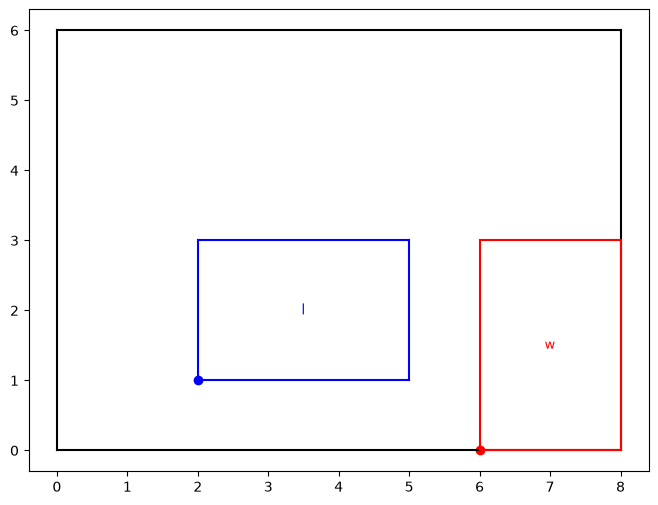

In [7]:
def plotar_caixa(bottom_left: list,
                 l: int,
                 w: int,
                 color: str,
                 label: str):

    x0, y0 = bottom_left
    plt.scatter(x = x0, y = y0, color = color)
    plt.plot([x0, x0 + l], [y0, y0], color = color)
    plt.plot([x0, x0], [y0, y0 + w], color = color)
    plt.plot([x0, x0 + l], [y0 + w, y0 + w], color = color)
    plt.plot([x0 + l, x0 + l], [y0, y0 + w], color = color)
    plt.text(x = x0 + l/2, y =y0 + w/2, s = label, color = color, fontsize = 9, ha = 'center', va = 'center')

def plotar_palete(L: int,
                  W: int):
    plt.figure(figsize = (8, 6))
    plt.plot ([0, L], [0, 0], 'k-')
    plt.plot ([0, 0], [0, W], 'k-')
    plt.plot ([0, L], [W, W], 'k-')
    plt.plot ([L, L], [0, W], 'k-')

plotar_palete(L, W)

plotar_caixa(bottom_left=[2, 1],
             l = 3,
             w = 2,
             color = 'blue',
             label = 'l')

plotar_caixa(bottom_left=[6, 0],
             l = 2,
             w = 3,
             color = 'red',
             label = 'w')

In [8]:
f_um = lambda n_um, l_um, n_dois, l_dois: n_um * l_um + n_dois * l_dois

f_dois = lambda n_um, w_um, n_dois, w_dois: n_um * w_um + n_dois * w_dois

In [9]:
# n_um: Número de caixas deitadas
# n_dois: Número de caixas de pé

print(f_um(n_um = 1, l_um = 3, n_dois = 2, l_dois = 2)) # p <= L - w_um
print(f_dois(n_um = 2, w_um = 2, n_dois = 0, w_dois = 3)) # q <= W - w_um

7
4


0 0 0
1 0 3
2 0 6
3 0 9
4 0 12
5 0 15
6 0 18
7 0 21
0 1 2
1 1 5
2 1 8
3 1 11
4 1 14
5 1 17
6 1 20
7 1 23
0 2 4
1 2 7
2 2 10
3 2 13
4 2 16
5 2 19
6 2 22
7 2 25
0 3 6
1 3 9
2 3 12
3 3 15
4 3 18
5 3 21
6 3 24
7 3 27
0 4 8
1 4 11
2 4 14
3 4 17
4 4 20
5 4 23
6 4 26
7 4 29
0 5 10
1 5 13
2 5 16
3 5 19
4 5 22
5 5 25
6 5 28
7 5 31
0 6 12
1 6 15
2 6 18
3 6 21
4 6 24
5 6 27
6 6 30
7 6 33
0 7 14
1 7 17
2 7 20
3 7 23
4 7 26
5 7 29
6 7 32
7 7 35


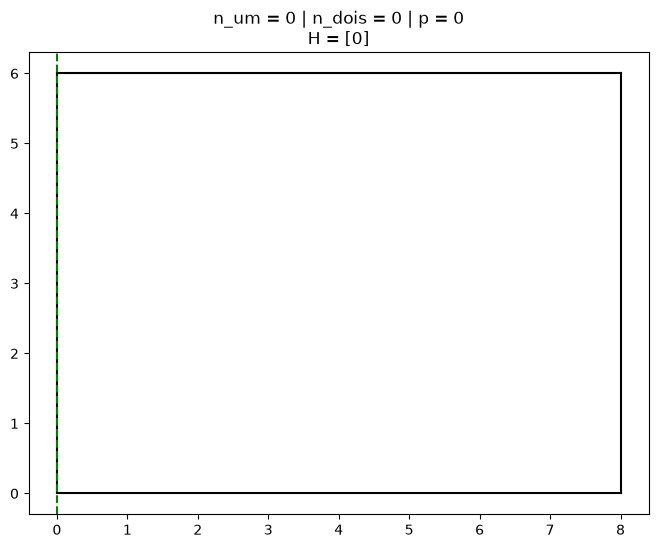

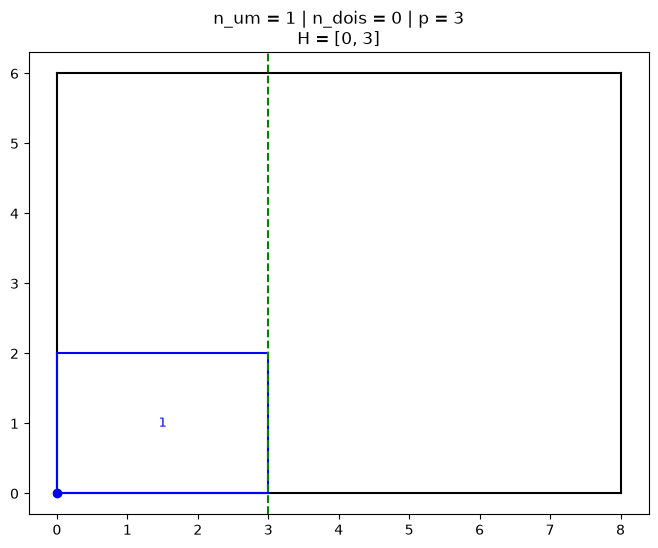

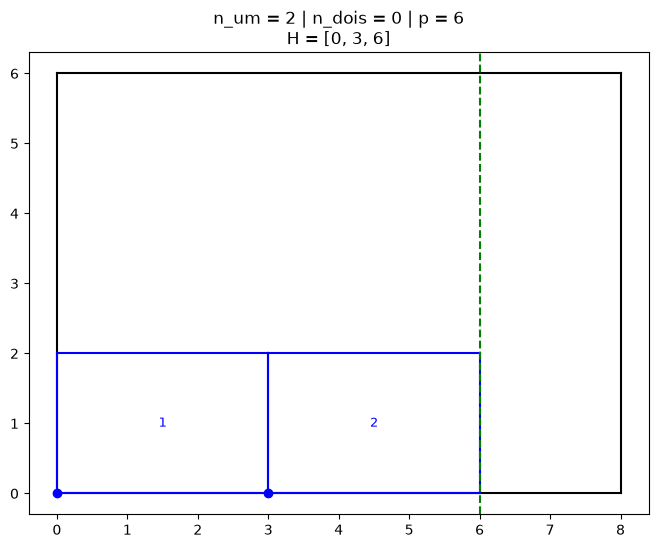

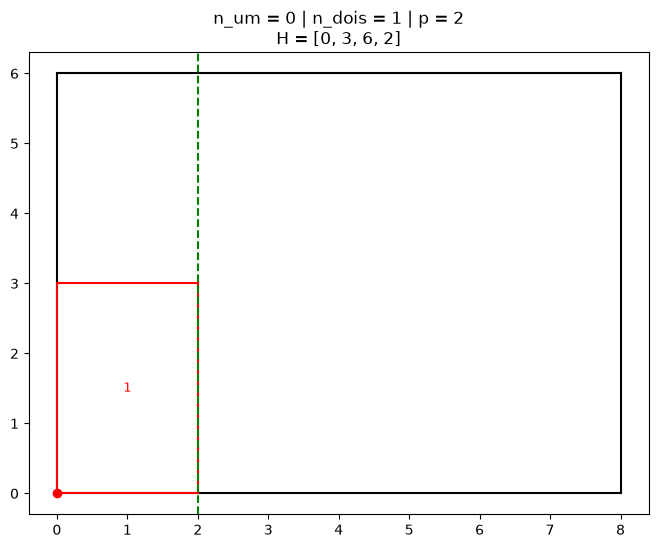

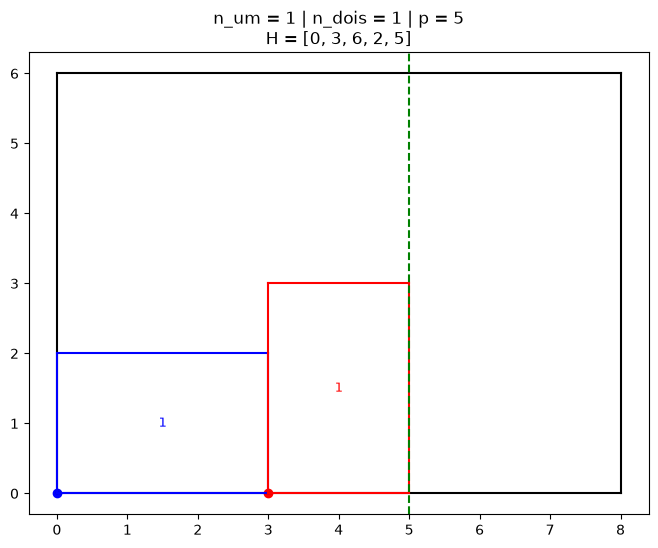

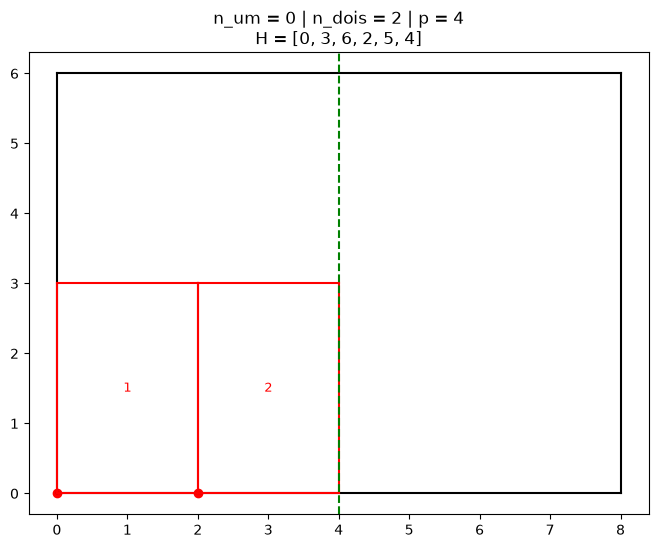

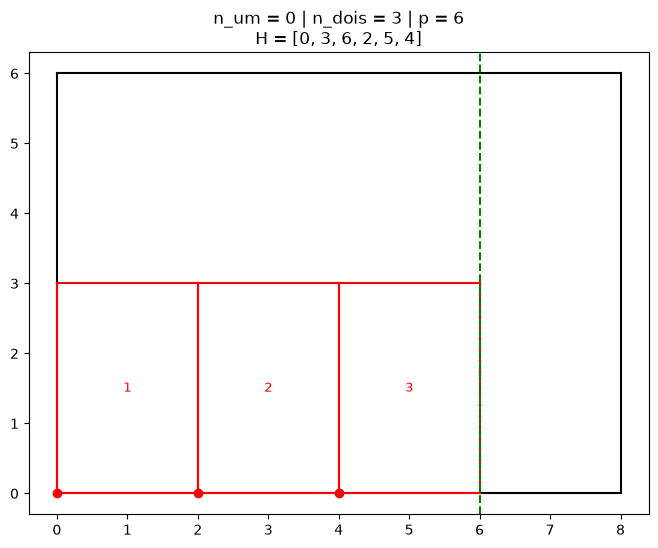

In [10]:
H = []

for n_dois, n_um in product(range(L), range(L)):
    # print(n_um, n_dois)
    p = f_um(n_um, l_um, n_dois, l_dois)
    print(n_um, n_dois, p)
    if p <= L - w_um:

        if p not in H:
            H.append(p)

        plotar_palete(L, W)

        for n in range(n_um):
            plotar_caixa(bottom_left = [n * l_um, 0], l = l_um, w = w_um, color = 'blue', label = n + 1)

        for n in range(n_dois):
            plotar_caixa(bottom_left = [n_um * l_um + n * l_dois, 0], l = l_dois, w = w_dois, color = 'red', label = n + 1)

        plt.axvline(x = p, color = 'green', linestyle = '--')
        plt.title(f'{n_um = } | {n_dois = } | {p = }\n{H = }')

In [11]:
H

[0, 3, 6, 2, 5, 4]

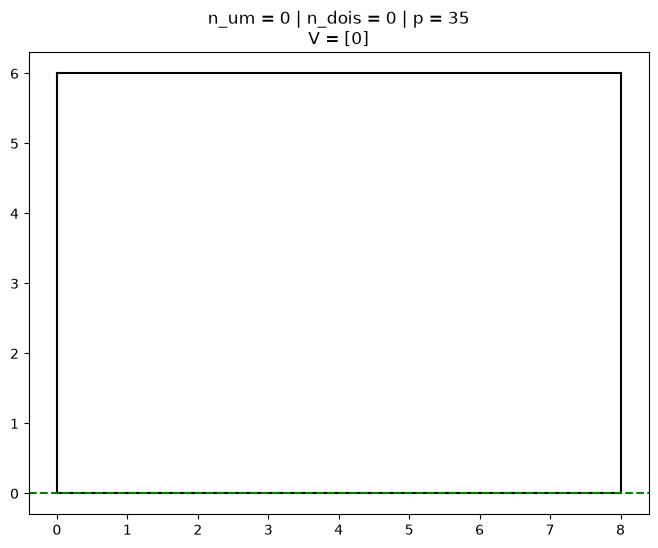

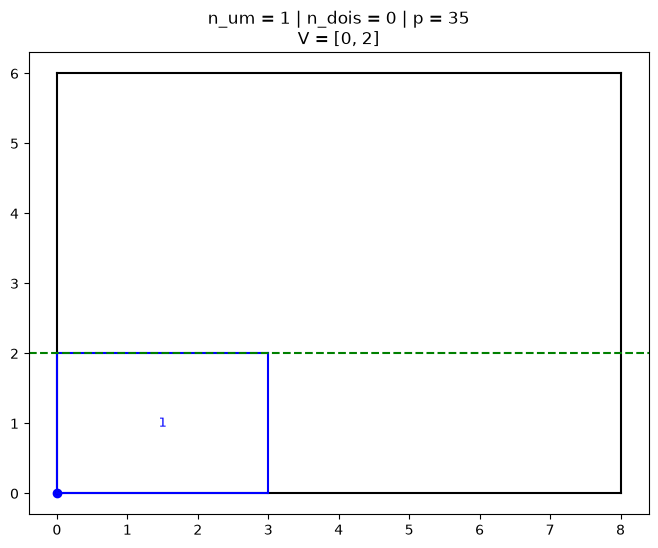

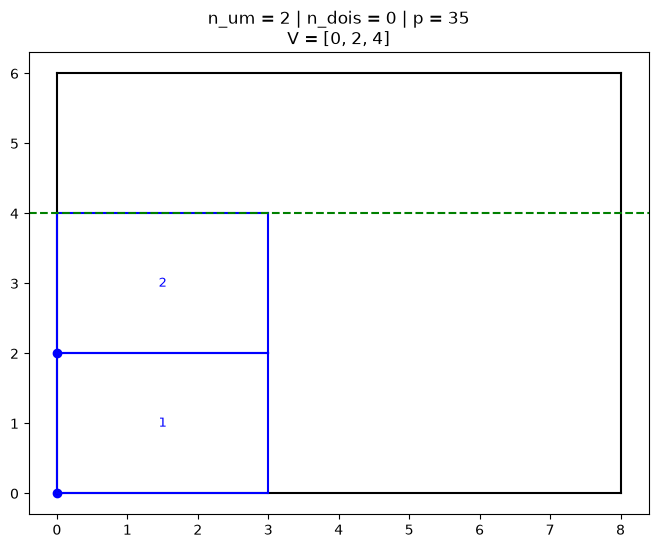

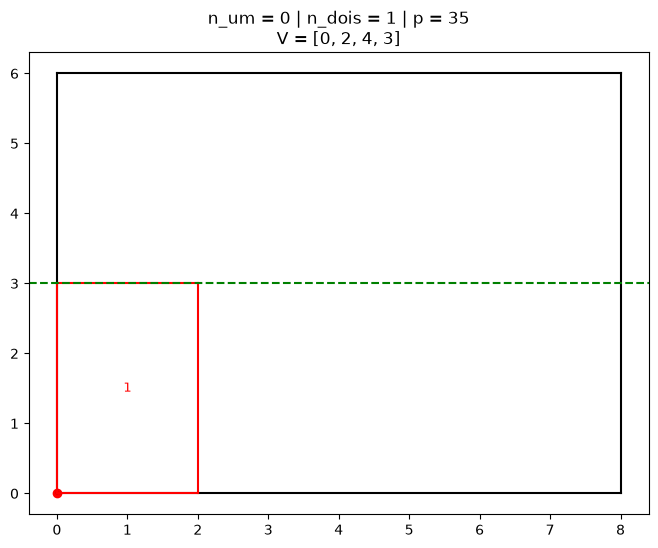

In [12]:
V = []

for n_dois, n_um in product(range(L), range(L)):
    # print(n_um, n_dois)
    q = f_dois(n_um, w_um, n_dois, w_dois)
    # print(n_um, n_dois, p)
    if q <= W - w_um:

        if q not in V:
            V.append(q)

        plotar_palete(L, W)

        for n in range(n_um):
            plotar_caixa(bottom_left = [0, n * w_um], l = l_um, w = w_um, color = 'blue', label = n + 1)

        for n in range(n_dois):
            plotar_caixa(bottom_left = [n_um * l_um + n * l_dois, 0], l = l_dois, w = w_dois, color = 'red', label = n + 1)

        plt.axhline(y = q, color = 'green', linestyle = '--')
        plt.title(f'{n_um = } | {n_dois = } | {p = }\n{V = }')

In [13]:
H = sorted(H)
V = sorted(V)
print(H)
print(V)

[0, 2, 3, 4, 5, 6]
[0, 2, 3, 4]


In [14]:
lista_rs = list(product(H, V))
display(lista_rs)

[(0, 0),
 (0, 2),
 (0, 3),
 (0, 4),
 (2, 0),
 (2, 2),
 (2, 3),
 (2, 4),
 (3, 0),
 (3, 2),
 (3, 3),
 (3, 4),
 (4, 0),
 (4, 2),
 (4, 3),
 (4, 4),
 (5, 0),
 (5, 2),
 (5, 3),
 (5, 4),
 (6, 0),
 (6, 2),
 (6, 3),
 (6, 4)]

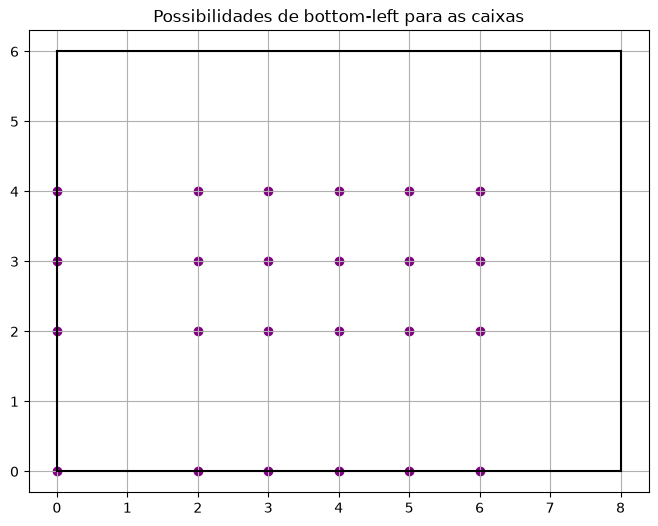

In [15]:
# pontos possíveis
if indice == 0:
    plotar_palete(L, W)
    for r, s in lista_rs:
        plt.scatter(x = r, y = s, color = 'purple')

    plt.title('Possibilidades de bottom-left para as caixas')
    plt.grid()
    plt.show()

In [16]:
ls = [l_um, l_dois]
ws = [w_um, w_dois]

In [17]:
i = 1
print(ls[i - 1], ws[i -1])

3 2


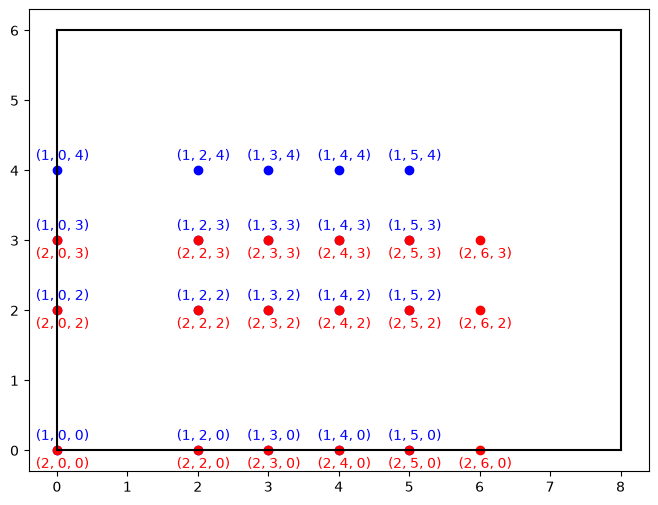

In [26]:
lista_variaveis = []

plotar_palete(L, W)

for i, (p, q) in product([1, 2], lista_rs):
    # print(i, p, q)
    # i = 1: caixa deitada
    # i = 2: caixa de pé
    if p + ls[i - 1] <= L and q + ws[i - 1] <= W: # Checa se cabe no palete
        lista_variaveis.append((i, p, q))

        if indice == 0:
            cor = 'blue' if i == 1 else 'red'
            plt.scatter(x = p, y = q, color = cor) # plotar o bottom-left

            if i == 1: # deitada
                plt.text(x = p - 0.3, y = q + 0.15, s = f"({i}, {p}, {q})", color = cor, fontsize = 10)
            else:
                plt.text(x = p - 0.3, y = q - 0.25, s = f"({i}, {p}, {q})", color = cor, fontsize = 10)

In [27]:
print(len(lista_variaveis))

38


In [28]:
prob = plp.LpProblem(name = 'Palete-Caixa',
                     sense = plp.LpMaximize)
display(prob)

Palete-Caixa:
MAXIMIZE
None
VARIABLES

In [30]:
dict_variaveis = plp.LpVariable.dicts(name = 'C',
                                      indices = lista_variaveis,
                                      lowBound = 0,
                                      upBound = 1,
                                      cat = plp.LpBinary)
display(dict_variaveis)

{(1, 0, 0): C_(1,_0,_0),
 (1, 0, 2): C_(1,_0,_2),
 (1, 0, 3): C_(1,_0,_3),
 (1, 0, 4): C_(1,_0,_4),
 (1, 2, 0): C_(1,_2,_0),
 (1, 2, 2): C_(1,_2,_2),
 (1, 2, 3): C_(1,_2,_3),
 (1, 2, 4): C_(1,_2,_4),
 (1, 3, 0): C_(1,_3,_0),
 (1, 3, 2): C_(1,_3,_2),
 (1, 3, 3): C_(1,_3,_3),
 (1, 3, 4): C_(1,_3,_4),
 (1, 4, 0): C_(1,_4,_0),
 (1, 4, 2): C_(1,_4,_2),
 (1, 4, 3): C_(1,_4,_3),
 (1, 4, 4): C_(1,_4,_4),
 (1, 5, 0): C_(1,_5,_0),
 (1, 5, 2): C_(1,_5,_2),
 (1, 5, 3): C_(1,_5,_3),
 (1, 5, 4): C_(1,_5,_4),
 (2, 0, 0): C_(2,_0,_0),
 (2, 0, 2): C_(2,_0,_2),
 (2, 0, 3): C_(2,_0,_3),
 (2, 2, 0): C_(2,_2,_0),
 (2, 2, 2): C_(2,_2,_2),
 (2, 2, 3): C_(2,_2,_3),
 (2, 3, 0): C_(2,_3,_0),
 (2, 3, 2): C_(2,_3,_2),
 (2, 3, 3): C_(2,_3,_3),
 (2, 4, 0): C_(2,_4,_0),
 (2, 4, 2): C_(2,_4,_2),
 (2, 4, 3): C_(2,_4,_3),
 (2, 5, 0): C_(2,_5,_0),
 (2, 5, 2): C_(2,_5,_2),
 (2, 5, 3): C_(2,_5,_3),
 (2, 6, 0): C_(2,_6,_0),
 (2, 6, 2): C_(2,_6,_2),
 (2, 6, 3): C_(2,_6,_3)}

In [33]:
# dict_variaveis.values()
prob += sum(dict_variaveis.values())
display(prob)

Palete-Caixa:
MAXIMIZE
1*C_(1,_0,_0) + 1*C_(1,_0,_2) + 1*C_(1,_0,_3) + 1*C_(1,_0,_4) + 1*C_(1,_2,_0) + 1*C_(1,_2,_2) + 1*C_(1,_2,_3) + 1*C_(1,_2,_4) + 1*C_(1,_3,_0) + 1*C_(1,_3,_2) + 1*C_(1,_3,_3) + 1*C_(1,_3,_4) + 1*C_(1,_4,_0) + 1*C_(1,_4,_2) + 1*C_(1,_4,_3) + 1*C_(1,_4,_4) + 1*C_(1,_5,_0) + 1*C_(1,_5,_2) + 1*C_(1,_5,_3) + 1*C_(1,_5,_4) + 1*C_(2,_0,_0) + 1*C_(2,_0,_2) + 1*C_(2,_0,_3) + 1*C_(2,_2,_0) + 1*C_(2,_2,_2) + 1*C_(2,_2,_3) + 1*C_(2,_3,_0) + 1*C_(2,_3,_2) + 1*C_(2,_3,_3) + 1*C_(2,_4,_0) + 1*C_(2,_4,_2) + 1*C_(2,_4,_3) + 1*C_(2,_5,_0) + 1*C_(2,_5,_2) + 1*C_(2,_5,_3) + 1*C_(2,_6,_0) + 1*C_(2,_6,_2) + 1*C_(2,_6,_3) + 0
VARIABLES
0 <= C_(1,_0,_0) <= 1 Integer
0 <= C_(1,_0,_2) <= 1 Integer
0 <= C_(1,_0,_3) <= 1 Integer
0 <= C_(1,_0,_4) <= 1 Integer
0 <= C_(1,_2,_0) <= 1 Integer
0 <= C_(1,_2,_2) <= 1 Integer
0 <= C_(1,_2,_3) <= 1 Integer
0 <= C_(1,_2,_4) <= 1 Integer
0 <= C_(1,_3,_0) <= 1 Integer
0 <= C_(1,_3,_2) <= 1 Integer
0 <= C_(1,_3,_3) <= 1 Integer
0 <= C_(1,_3,_4) <= 1 Integ